# 이미지 정보 추출 — 상품 이미지 분석 / 객체 인식 / 속성 추출 / JSON 출력

이커머스에서 가장 활용도가 높은 시나리오인 **상품 이미지 분석**을 중심으로,
"카테고리 분류 → 객체 나열 → 속성 추출 → 하나의 JSON"까지 단계적으로 확장합니다.

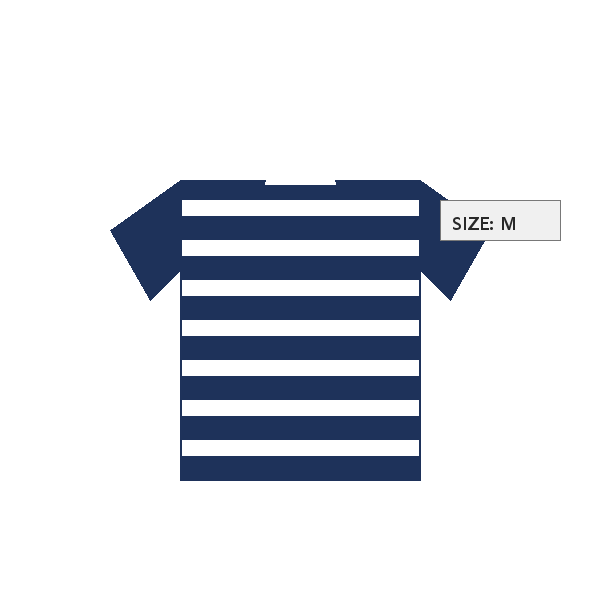

In [1]:
from vlm_utils import ask, ask_json, show

PRODUCT = "./data/product.png"
show(PRODUCT)

## 상품 이미지 분석
프롬프트에 **쇼핑몰 카테고리 체계**를 함께 제시하면 분류 정확도가 올라갑니다.

In [3]:
category = ask(
    PRODUCT,
    "이 상품 이미지를 분석해서 아래 카테고리 중 하나로만 답하고, "
    "이유를 한 문장으로 덧붙여줘.\n"
    "카테고리: [의류, 신발, 가방, 액세서리, 가전, 기타]",
)
print(category)

의류, 이유: 이미지에 상의가 보이며, 상품은 옷임을 명확히 나타냄.


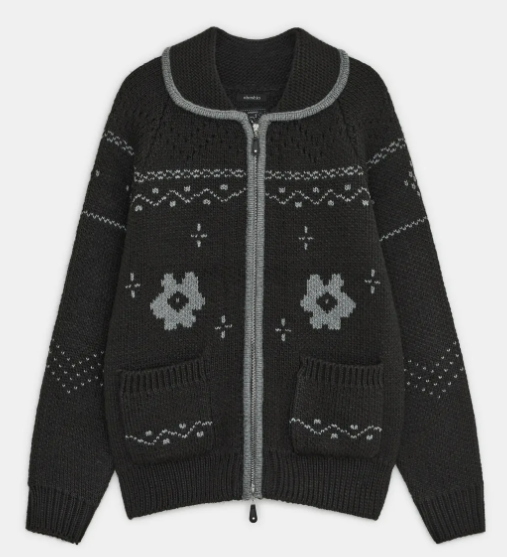

In [9]:
PRODUCT02 = "./data/product02.png"
show(PRODUCT02)

In [4]:
category = ask(
    PRODUCT02,
    "이 상품 이미지를 분석해서 아래 카테고리 중 하나로만 답하고, "
    "이유를 한 문장으로 덧붙여줘.\n"
    "카테고리: [의류, 신발, 가방, 액세서리, 가전, 기타]",
)
print(category)

카테고리: 의류  
이미지는 스웨터를 보여서 의류 범주에 속합니다.


## 객체 인식 (Object Recognition)

In [5]:
objects = ask(
    PRODUCT,
    "이미지에 보이는 모든 객체를 나열하고, 각 객체의 대략적인 위치"
    "(왼쪽 위/가운데/오른쪽 아래 등)를 함께 알려줘.",
)
print(objects)

이미지에 보이는 객체는 다음과 같습니다:

1. **가로줄무늬 티셔츠**  
   - 위치: **가운데**  
   - 설명: 어두운 파란색 바탕에 흰색 가로 줄무늬가 7개 정도 있는 반팔 티셔츠입니다. 왼쪽 어깨에서 오른쪽 어깨까지 흐르는 형태로, 상단에는 흰색 라인을 따라 티셔츠의 윗부분이 보입니다.  
   - 세부 설명: 오른쪽 어깨 부분에 'SIZE: M'이라고 적힌 박스가 부착되어 있습니다.

2. **SIZE: M 라벨**  
   - 위치: **오른쪽 위** (티셔츠의 오른쪽 어깨 위쪽)  
   - 설명: 흰색 배경에 검은색 글씨로 "SIZE: M"이 쓰인 직사각형 레이블입니다. 티셔츠의 오른쪽 어깨 위쪽에 부착되어 있는 것으로 보입니다.

---

이미지에는 총 **2개의 객체**가 있으며, 이 객체들은 각각 **가운데**와 **오른쪽 위**에 위치하고 있습니다.


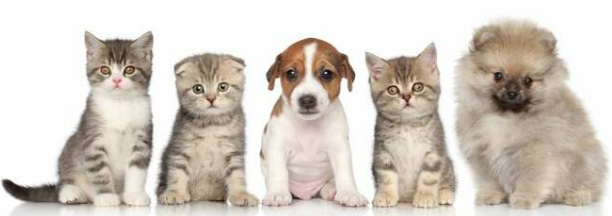

In [7]:
PRODUCT03 = "./data/product03.png"
show(PRODUCT03)

In [8]:
objects = ask(
    PRODUCT03,
    "이미지에 보이는 모든 객체를 나열하고, 각 객체의 대략적인 위치"
    "(왼쪽 위/가운데/오른쪽 아래 등)를 함께 알려줘.",
)
print(objects)

이미지에 보이는 객체는 다음과 같습니다:

1. **왼쪽에 앉은 고양** — 이미지의 왼쪽 가장자리에 위치. 회색 줄무늬와 흰색 몸통을 가진 고양. 눈은 노란빛이며, 귀는 둥근 모양.
2. **두 번째 고양** — 첫 번째 고양 오른쪽. 회색 줄무늬 고양으로, 눈이 흰색 바탕에 빨간빛이 있는 듯한 표현. 귀는 둥근 모양.
3. **중간에 앉은 개** — 중앙에 위치. 갈색과 흰색이 섞인 개로, 코와 입 주변은 흰색이며, 눈은 검은색.
4. **네 번째 고양** — 중앙 개의 오른쪽. 회색 줄무늬 고양으로, 눈이 노란빛이며, 귀는 둥근 모양.
5. **오른쪽에 앉은 개** — 이미지의 오른쪽 가장자리에 위치. 털이 흰색으로, 귀는 둥근 모양. 눈은 검은색이며, 코는 검은색.

이 모든 객체는 흰색 배경 위에 배치되어 있으며, 모두 앉아 있는 자세를 취하고 있습니다.


## 속성 추출 (Attribute Extraction)
추출할 속성 목록을 미리 정의해주고, 이미지에 없는 속성은
**"unknown"으로 표기**하도록 지시해 근거 없는 추측을 막습니다.
(이 상품 이미지에는 "넥라인"이 명확히 보이지 않으므로 unknown이 나오는지 확인해보세요.)

In [10]:
attributes = ask_json(
    PRODUCT,
    '''
다음 속성만 추출해서 JSON으로만 답해: color, material, pattern, neckline, sleeve_length.
해당 속성이 이미지에서 명확히 확인되지 않으면 값으로 "unknown"을 넣어.
''',
)
print(attributes)

{'color': 'blue', 'material': 'unknown', 'pattern': 'striped', 'neckline': 'round', 'sleeve_length': 'short'}


In [11]:
attributes = ask_json(
    PRODUCT02,
    '''
다음 속성만 추출해서 JSON으로만 답해: color, material, pattern, neckline, sleeve_length.
해당 속성이 이미지에서 명확히 확인되지 않으면 값으로 "unknown"을 넣어.
''',
)
print(attributes)

{'color': 'black', 'material': 'knit', 'pattern': 'floral, geometric', 'neckline': 'stand collar', 'sleeve_length': 'full'}


## JSON 출력으로 파이프라인 통합
카테고리 + 객체 + 속성을 **하나의 스키마**로 합쳐 한 번에 뽑아봅니다.
이렇게 나온 JSON은 DB 적재·검색 인덱싱·추천 시스템 입력으로 바로 활용할 수 있습니다.

In [12]:
combined_schema = '''
아래 JSON 스키마로만 답해. 다른 텍스트는 출력하지 마.
{
  "category": "string",
  "objects": ["string"],
  "attributes": {
    "color": "string",
    "material": "string",
    "pattern": "string"
  }
}
'''
combined = ask_json(PRODUCT, combined_schema)
print(combined)
assert "category" in combined and "attributes" in combined

{'category': 'clothing', 'objects': ['shirt'], 'attributes': {'color': 'blue', 'material': 'fabric', 'pattern': 'striped'}}


In [13]:
combined = ask_json(PRODUCT02, combined_schema)
print(combined)
assert "category" in combined and "attributes" in combined

{'category': 'outerwear', 'objects': ['cardigan'], 'attributes': {'color': 'black', 'material': 'knit', 'pattern': 'floral'}}
